# Data Preparation

* Charging Sessions

  @Description of Fields of Charging Session Dataset
  
  *  **basic infos**  
  timezone  ——
  siteID    ——   Unique identifier for the site.   
  spaceID   ——     Unique identifier of the parking space.   
  stationID  ——   Unique identifier of the charging point.   

  *  **user level**  
  userID    ——   Unique identifier of the user, if provided.   
  userInputs  —— only available if the user participates in app-based charging.  
   
   *  **session level** 
   *  **recorded session**  /string   
   id —— Unique identifier of the session record   
   sessionID —— Unique identifier for the session.   
   
    *  **charging duration**  /datetime  
      * requested charging duration    
        modifiedAt  —— Time this user input was provided.   
        requestedDeparture —— User estimated departure time. 
        minutesAvailable —— Length of the session as estimated by the user.   
      * recorded charging duration   
        connectionTime —— Time when the EV plugged in.   
        disconnectTime —— Time when the EV unplugged.   
        doneChargingTime —— Time of the last non-zero current draw recorded.   
    
    *  **charging energy and driving range**  /float  
      * requested charging energy and driving range  
        kWhRequested —— Energy requested by the user in kWh.   
        milesRequested —— Number of miles requested by the user.     
      * recorded charging energy  
        kWhDelivered —— Amount of energy delivered during the session.  
      * Efficiency  
        WhPerMile —— Efficiency of the EV in Wh per mile.   

    *  **payment**  /bool  
     paymentRequired —— If the user was required to pay for this session.   

    



In [1]:
import pandas as pd
import ast

# charging data process
charging_sessions = pd.read_csv(
    "Data Share/charging_sessions.csv",
    index_col=0,
    dtype={"userID": str, "siteID": str}
)

# Remove identical records; check conflicting session IDs separately.
charging_sessions = charging_sessions.drop_duplicates().reset_index(drop=True)
charging_sessions["siteID"] = pd.to_numeric(charging_sessions["siteID"]).astype("Int64")

# userInputs
user_inputs = charging_sessions["userInputs"].fillna("[]").apply(
    ast.literal_eval
).apply(lambda x: x[0] if x else {})
user_inputs = pd.DataFrame(
    user_inputs.tolist(), index=charging_sessions.index
).add_prefix("input_")
charging_sessions = charging_sessions.join(user_inputs)

# Keep raw userInputs for later analysis of revised requests.
for column in ["connectionTime", "disconnectTime", "doneChargingTime",
               "input_modifiedAt", "input_requestedDeparture"]:
    charging_sessions[column] = pd.to_datetime(
        charging_sessions[column], utc=True, errors="coerce"
    ).dt.tz_convert("America/Los_Angeles")

# Calculate Durations
# Connected Duration
charging_sessions["connected_duration_hours"] = (charging_sessions["disconnectTime"] - charging_sessions["connectionTime"]).dt.total_seconds() / 3600
# Charging Duration
charging_sessions["charging_duration_hours"] = (charging_sessions["doneChargingTime"] - charging_sessions["connectionTime"]).dt.total_seconds() / 3600

# anomalous records
# anomalous1: connectionTime" or "disconnectTime“ is missing
charging_sessions["invalid_connection_time"] = (
    charging_sessions[["connectionTime", "disconnectTime"]].isna().any(axis=1)
    | charging_sessions["connected_duration_hours"].lt(0)
)
# anomalous2: doneChargingTime is missing
charging_sessions["missing_done_time"] = charging_sessions["doneChargingTime"].isna()
# anomalous3: doneChargingTime is earlier than connectionTime or later than disconnectTime
charging_sessions["invalid_done_time"] = (
    charging_sessions["doneChargingTime"].lt(charging_sessions["connectionTime"])
    | charging_sessions["doneChargingTime"].gt(charging_sessions["disconnectTime"])
)

# fillna with anomalous
charging_sessions.loc[charging_sessions["invalid_connection_time"], "connected_duration_hours"] = float("nan")
charging_sessions.loc[charging_sessions["invalid_connection_time"] | charging_sessions["invalid_done_time"], "charging_duration_hours"] = float("nan")


def column_summary(frame):
    """Summarize data types and missing values for every column."""
    return pd.DataFrame({
        "Data type": frame.dtypes.astype(str),
        "Missing values": frame.isna().sum(),
        "Missing (%)": (frame.isna().mean() * 100).round(2),
    }).rename_axis("Column")

print("Charging sessions")
print("Duplicate charging session IDs:", charging_sessions["sessionID"].duplicated().sum())
print(column_summary(charging_sessions))


Charging sessions
Duplicate charging session IDs: 0
                                                    Data type  Missing values  \
Column                                                                          
id                                                     object               0   
connectionTime            datetime64[ns, America/Los_Angeles]               0   
disconnectTime            datetime64[ns, America/Los_Angeles]               0   
doneChargingTime          datetime64[ns, America/Los_Angeles]            4087   
kWhDelivered                                          float64               0   
sessionID                                              object               0   
siteID                                                  Int64               0   
spaceID                                                object               0   
stationID                                              object               0   
timezone                                               ob

In [51]:
# weather
weather = pd.read_csv('Data Share/weather_burbank_airport.csv')
weather["timestamp"] = pd.to_datetime(weather["timestamp"])

print("weather")
print(column_summary(weather))
print("Duplicate weather rows:", weather.duplicated().sum())

weather
                              Data type  Missing values  Missing (%)
Column                                                              
city                             object               0         0.00
timestamp                datetime64[ns]               0         0.00
temperature                     float64              25         0.09
cloud_cover                     float64              20         0.07
cloud_cover_description          object              20         0.07
pressure                        float64               8         0.03
windspeed                       float64              86         0.29
precipitation                   float64               0         0.00
felt_temperature                float64              26         0.09
Duplicate weather rows: 0


**Data-quality finding.**   
Deduplication leaves 65,037 sessions: 33,629 at site 1 and 31,408 at site 2.  
Session identifiers are unique. Approximately 13.07% of connection-to-last-current durations are unavailable after validation.   
Connection times, disconnection times and delivered energy support the main analysis;   
charging-completion-based measures have weaker coverage. Weather is not used in the models because its timezone and coverage require separate alignment.

## Data Explore

In [52]:
# Check one-to-one ID mappings, rather than correlations between arbitrary codes.
id_columns = ["id", "sessionID", "siteID", "spaceID", "stationID", "userID", "input_userID"]
print(charging_sessions[id_columns].agg(["count", "nunique"]).T)

              count  nunique
id            65037    65037
sessionID     65037    65037
siteID        65037        2
spaceID       65037      107
stationID     65037      107
userID        47822     1006
input_userID  47822     1006


**Identifier finding.** The file contains 65,037 distinct session identifiers and 107 charging-point identifiers. Non-missing user identifiers describe only the identified subset and should not be interpreted as the entire user population.

In [53]:
# 1st check, check relationship
from itertools import combinations
#print("1st review of charging sessions")
summary = charging_sessions.describe(include="all").T
summary["unique"] = charging_sessions.nunique()
# display_table(summary.T)

# Count unique mappings in both directions.
def relationship_check(data, column_a, column_b):
    # Check both directions separately.
    for source, target in [(column_a, column_b), (column_b, column_a)]:
        counts = data.groupby(source)[target].nunique()

        if counts.empty:
            print(f"{source} → {target}: no data to check!")
        elif counts.eq(1).all():
            print(f"1 {source} -> 1 {target}")
        else:
            if counts.gt(1).any():
                print(f"{source} -> multiple {target}:")
                # display_table(counts[counts > 1].to_frame(f"{target}_count"))

            if counts.eq(0).any():
                print(f"some {source} values have no {target}:")
                # display_table(counts[counts == 0].to_frame(f"{target}_count"))

    print("*********")


columns = ["siteID", "spaceID", "stationID", "userID", "input_userID"]

# Check every pair of ID columns.
for column_a, column_b in combinations(columns, 2):
    relationship_check(charging_sessions, column_a, column_b)
    print()
    
relationship_check(charging_sessions, 'id', 'sessionID')
relationship_check(charging_sessions, 'connectionTime', 'disconnectTime')
relationship_check(charging_sessions, 'connectionTime', 'doneChargingTime')


siteID -> multiple spaceID:
1 spaceID -> 1 siteID
*********

siteID -> multiple stationID:
1 stationID -> 1 siteID
*********

siteID -> multiple userID:
userID -> multiple siteID:
*********

siteID -> multiple input_userID:
input_userID -> multiple siteID:
*********

1 spaceID -> 1 stationID
1 stationID -> 1 spaceID
*********

spaceID -> multiple userID:
some spaceID values have no userID:
userID -> multiple spaceID:
*********

spaceID -> multiple input_userID:
some spaceID values have no input_userID:
input_userID -> multiple spaceID:
*********

stationID -> multiple userID:
some stationID values have no userID:
userID -> multiple stationID:
*********

stationID -> multiple input_userID:
some stationID values have no input_userID:
input_userID -> multiple stationID:
*********

1 userID -> 1 input_userID
1 input_userID -> 1 userID
*********

1 id -> 1 sessionID
1 sessionID -> 1 id
*********
connectionTime -> multiple disconnectTime:
disconnectTime -> multiple connectionTime:
*********


**Mapping interpretation.** The observed mappings are one-to-one for `id`/`sessionID`, `spaceID`/`stationID`, and non-missing `userID`/`input_userID`. These are candidate redundant representations, not independent behavioral predictors. Timestamp pairs are not unique identifiers. Mapping consistency does not establish the semantics of partially populated user fields at the anonymous site.

One-to-one mappings indicate potentially redundant fields, not duplicate rows.
Missing IDs are reported separately and are not treated as one user.

In [54]:
# Keep original IDs for mapping and longitudinal analysis.
# The site IDs and duplicate records were already cleaned before exploration.
quality_columns = ["invalid_connection_time", "missing_done_time", "invalid_done_time"]
print(charging_sessions.groupby("siteID")[quality_columns].sum())

        invalid_connection_time  missing_done_time  invalid_done_time
siteID                                                               
1                             0               2037               3208
2                             0               2050               1206


**Anomaly interpretation.** Site 1 has 2,037 missing completion times and 3,208 invalid completion times; site 2 has 2,050 and 1,206, respectively. No invalid connection intervals were found. Invalid elapsed charging durations are excluded while the remaining session information is retained.

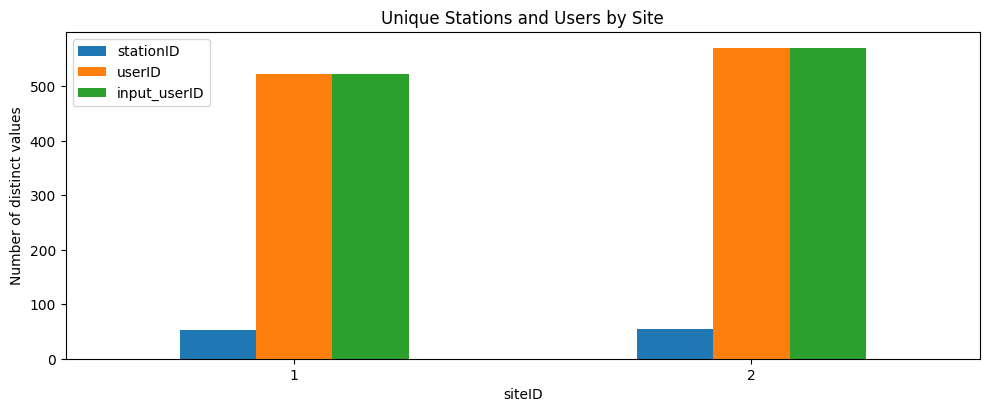

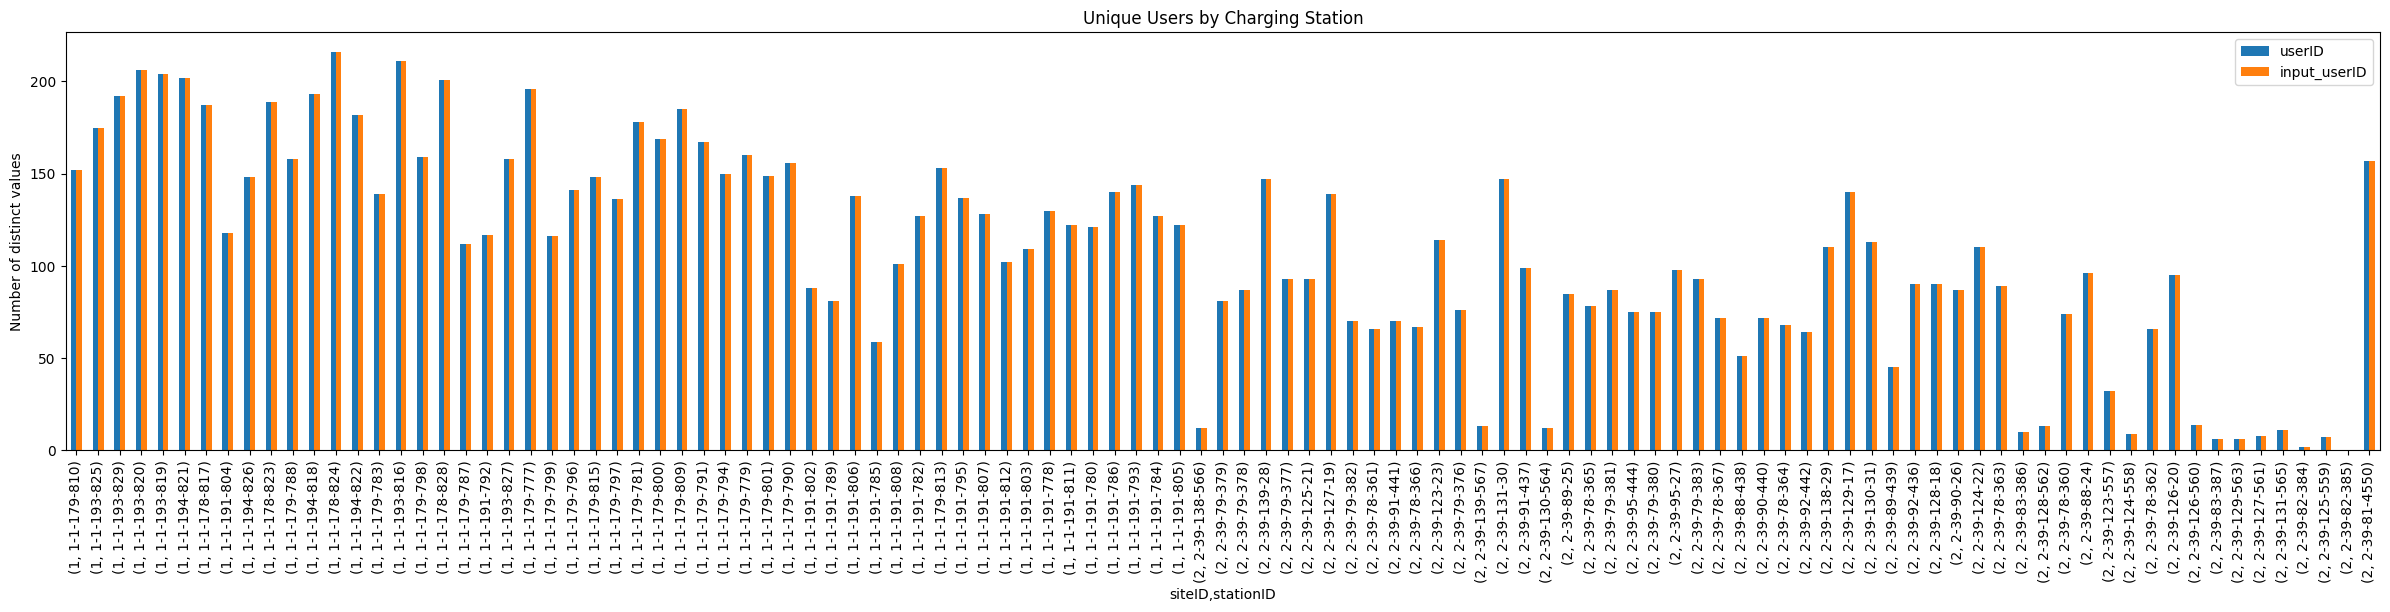

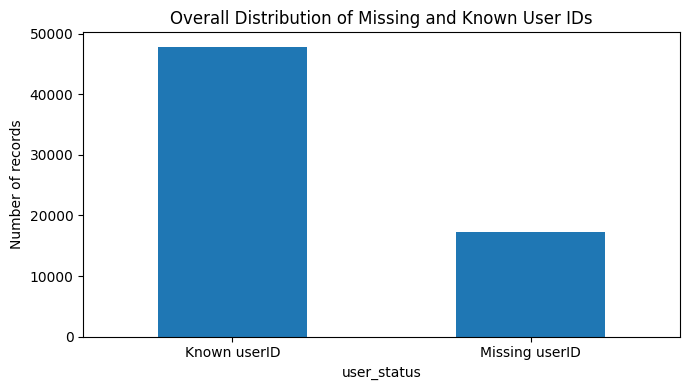

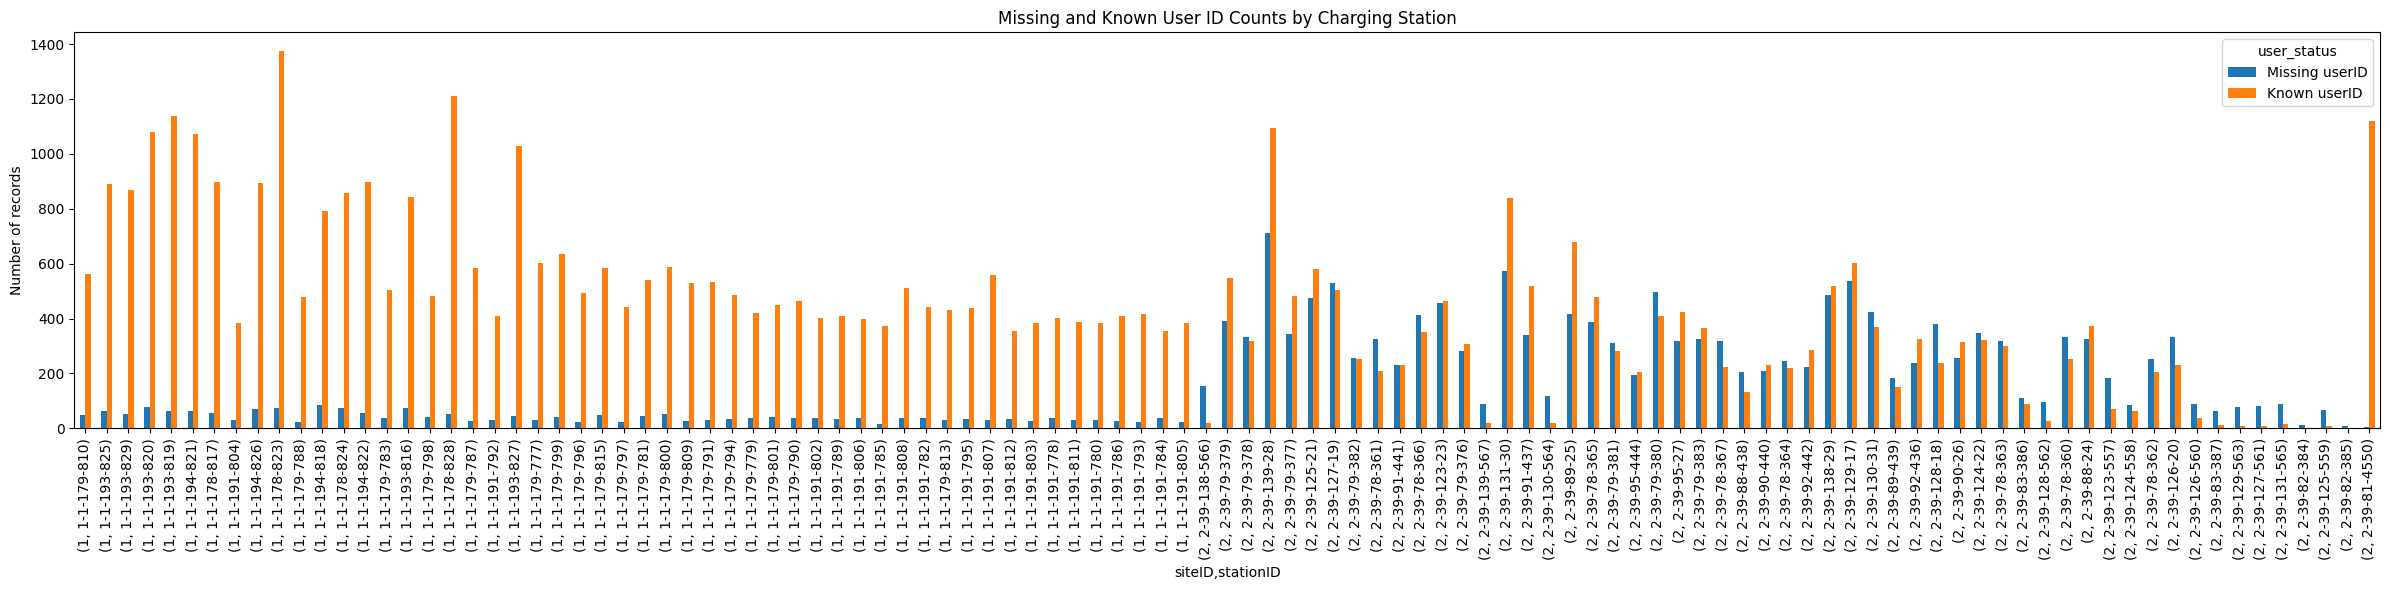

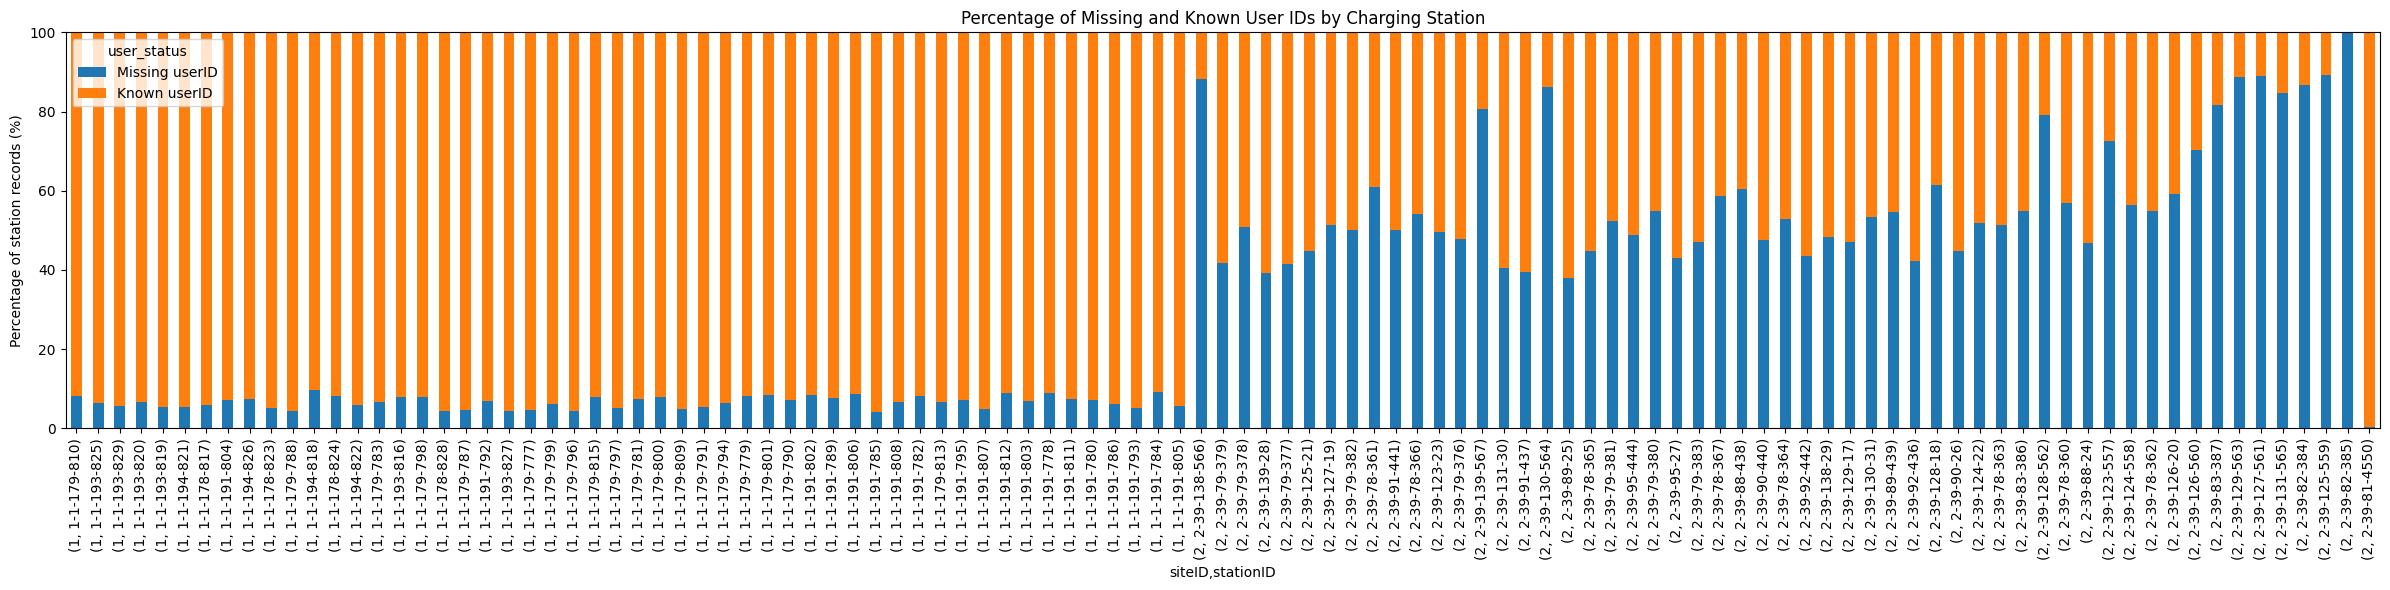

In [55]:
# 2nd check - check for charging location
# Group progressively by site, station, and user.
import matplotlib.pyplot as plt

# Figure 1
# Plot by Location
# plot distinct stations and users per site.
charging_sessions.groupby("siteID", sort=False, dropna=False)[
    ["stationID", "userID", "input_userID"]
].nunique().plot.bar(figsize=(10, 4))
plt.ylabel("Number of distinct values")
plt.xticks(rotation=0)
plt.tight_layout()
plt.title("Unique Stations and Users by Site")
plt.show()

# Figure 2
# plot distinct users per station within each site.
charging_sessions.groupby(["siteID", "stationID"], sort=False, dropna=False)[
    ["userID", "input_userID"]
].nunique().plot.bar(figsize=(24, 6))
plt.ylabel("Number of distinct values")
plt.xticks(rotation=90)
plt.tight_layout()
plt.title("Unique Users by Charging Station")
plt.show()

# Plot by whether userID is missing.
data = charging_sessions.assign(
    user_status=charging_sessions["userID"].isna().map({
        True: "Missing userID",
        False: "Known userID"
    })
)

# Figure 3
# Compare overall record counts.
data["user_status"].value_counts().plot.bar(
    figsize=(7, 4), rot=0
)
plt.ylabel("Number of records")
plt.title("Records with and without userID")
plt.tight_layout()
plt.title("Overall Distribution of Missing and Known User IDs")
plt.show()

# Count records by site, station, and user status.
station_counts = data.groupby(
    ["siteID", "stationID", "user_status"],
    sort=False,
    dropna=False,
    observed=True
).size().unstack("user_status", fill_value=0)

station_counts = station_counts.reindex(
    columns=["Missing userID", "Known userID"], fill_value=0
)

# Figure 4
# Compare record counts at each station.
station_counts.plot.bar(figsize=(24, 6))
plt.ylabel("Number of records")
plt.title("Records with and without userID by Station")
plt.xticks(rotation=90)
plt.tight_layout()
plt.title("Missing and Known User ID Counts by Charging Station")
plt.show()

# Compare percentages within each station.
station_percent = station_counts.div(
    station_counts.sum(axis=1), axis=0
) * 100

# Figure 5
station_percent.plot.bar(stacked=True, figsize=(24, 6))
plt.ylabel("Percentage of station records (%)")
plt.title("Share of Missing and Known userID within Each Station")
plt.ylim(0, 100)
plt.xticks(rotation=90)
plt.tight_layout()
plt.title("Percentage of Missing and Known User IDs by Charging Station")
plt.show()

Grouped by: siteID


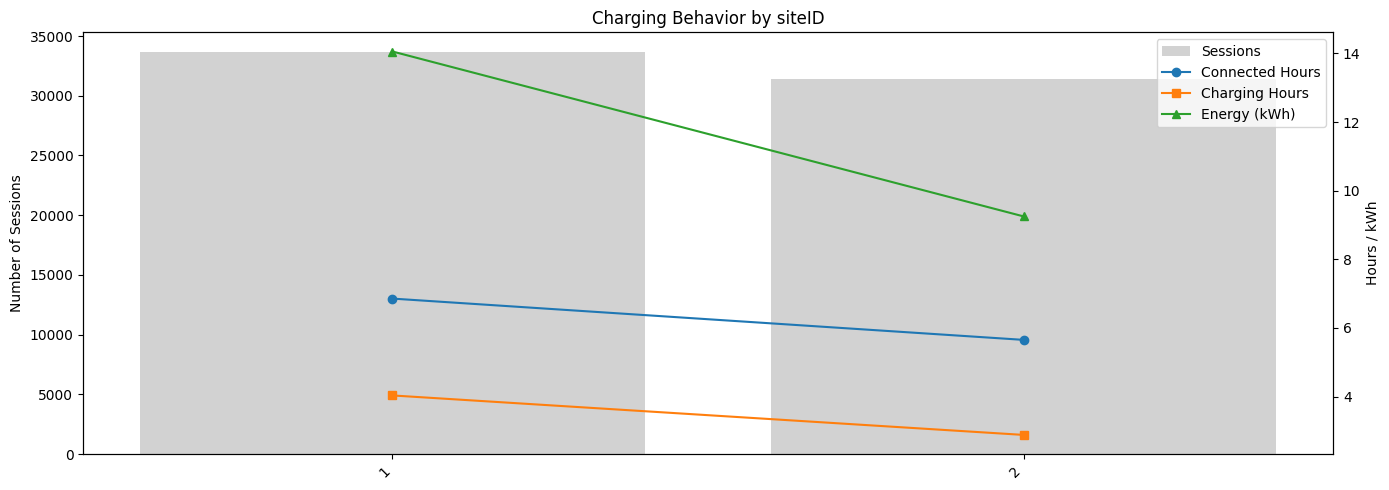

Grouped by: siteID, stationID


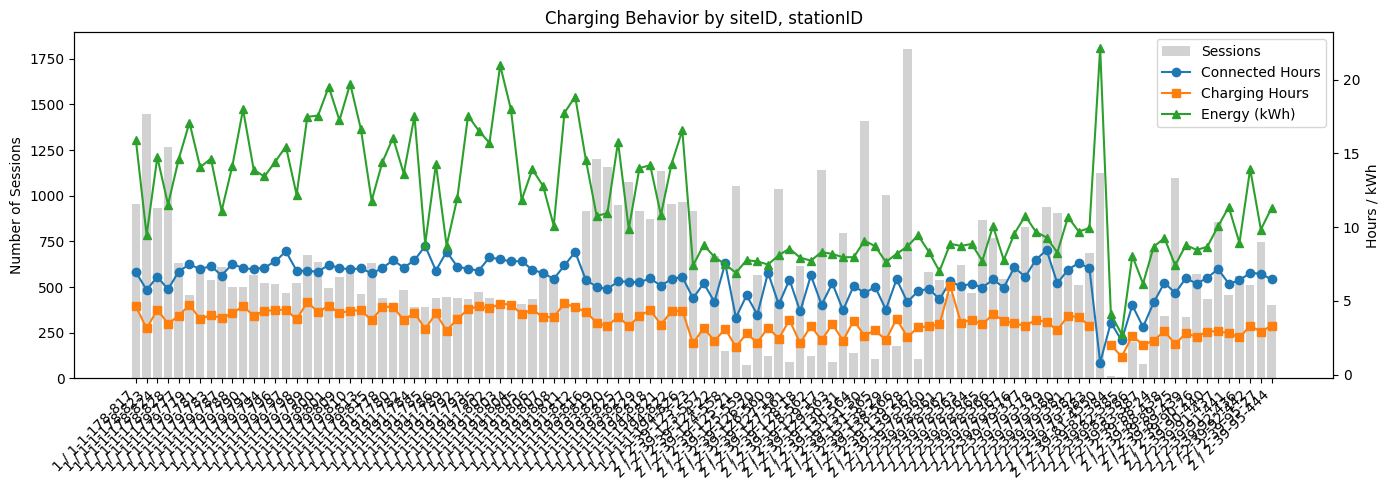

In [56]:
# Summaries by site, charging point and known user.
group_columns = ["siteID", "stationID"]
group_results = {}

for level in range(1, len(group_columns) + 1):
    columns = group_columns[:level]

    data = (
        charging_sessions.dropna(subset=["userID"])
        if "userID" in columns else charging_sessions
    )

    summary = data.groupby(columns, dropna=False).agg(
        session_count=("sessionID", "size"),
        mean_connected_hours=("connected_duration_hours", "mean"),
        mean_charging_hours=("charging_duration_hours", "mean"),
        valid_charging_duration_count=("charging_duration_hours", "count"),
        mean_energy_kWh=("kWhDelivered", "mean")
    ).reset_index()

    group_results[level] = summary

    # 1. Display table
    print("Grouped by:", ", ".join(columns))

    # 2. Multi-Y visualization
    labels = summary[columns].astype(str).agg(" / ".join, axis=1)
    x = np.arange(len(summary))

    fig, ax1 = plt.subplots(figsize=(14, 5))

    # Left Y-axis: Session count
    bars = ax1.bar(
        x, summary["session_count"],
        alpha=0.35, color="gray",
        label="Sessions"
    )
    ax1.set_ylabel("Number of Sessions")

    # Right Y-axis: Duration and energy
    ax2 = ax1.twinx()

    lines = [
        ax2.plot(x, summary["mean_connected_hours"],
                 marker="o", label="Connected Hours")[0],
        ax2.plot(x, summary["mean_charging_hours"],
                 marker="s", label="Charging Hours")[0],
        ax2.plot(x, summary["mean_energy_kWh"],
                 marker="^", label="Energy (kWh)")[0]
    ]

    ax2.set_ylabel("Hours / kWh")

    ax1.set_xticks(x)
    ax1.set_xticklabels(labels, rotation=45, ha="right")

    ax1.set_title(f"Charging Behavior by {', '.join(columns)}")

    ax1.legend(
        [bars] + lines,
        ["Sessions"] + [line.get_label() for line in lines],
        loc="upper right"
    )

    plt.tight_layout()
    plt.show()

Months with no records at either site:
PeriodIndex(['2020-09', '2020-10'], dtype='period[M]', name='Month')


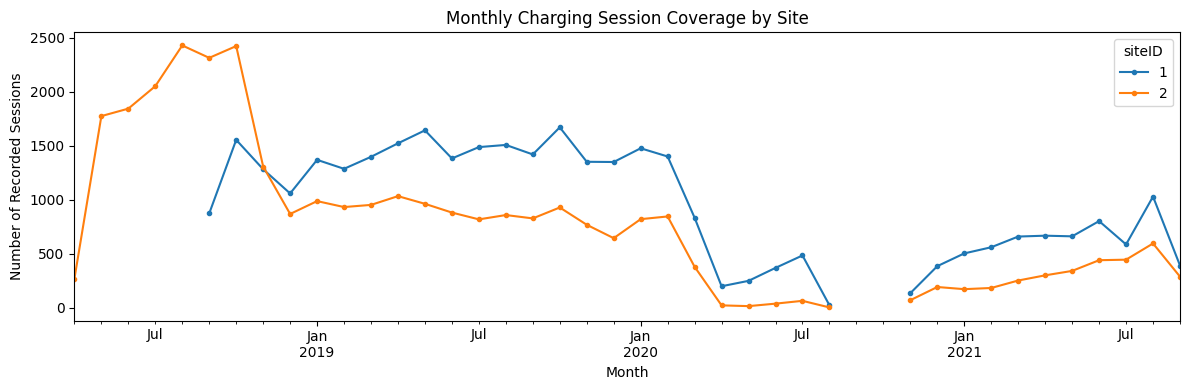

In [57]:
# Monthly record coverage in local time; leave missing months as NaN.
local_month = charging_sessions["connectionTime"].dt.tz_localize(None).dt.to_period("M")
monthly_sessions = charging_sessions.groupby([local_month, "siteID"]).size().unstack()
monthly_sessions = monthly_sessions.reindex(
    pd.period_range(local_month.min(), local_month.max(), freq="M")
)
monthly_sessions.index.name = "Month"
print("Months with no records at either site:")
print(monthly_sessions.index[monthly_sessions.isna().all(axis=1)])
monthly_sessions.plot(
    figsize=(12, 4),
    marker=".",
    title="Monthly Charging Session Coverage by Site",
    xlabel="Month",
    ylabel="Number of Recorded Sessions"
)
plt.tight_layout()
plt.show()


**Figure interpretation — monthly record coverage.** The curves show recorded sessions, not independently verified demand. Both sites have no records in September–October 2020; these gaps remain NaN. Low counts during other months may reflect activity changes, operational conditions or collection coverage. The plot alone cannot distinguish these explanations, and the first and last months may be partial.

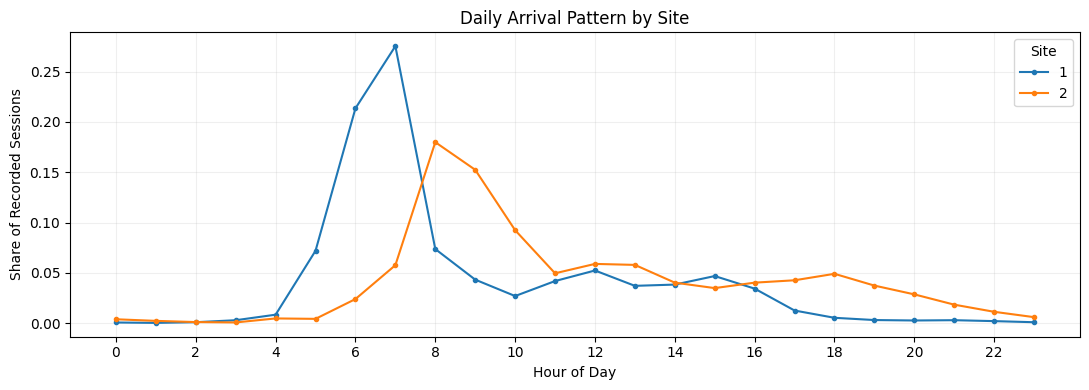

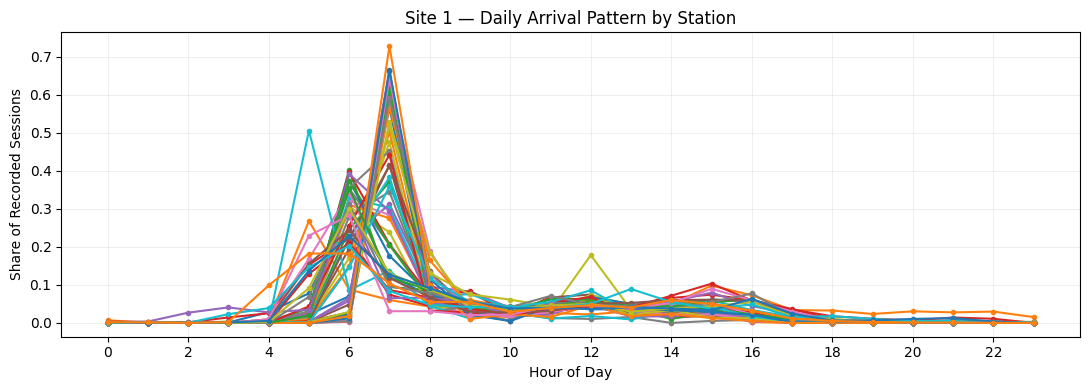

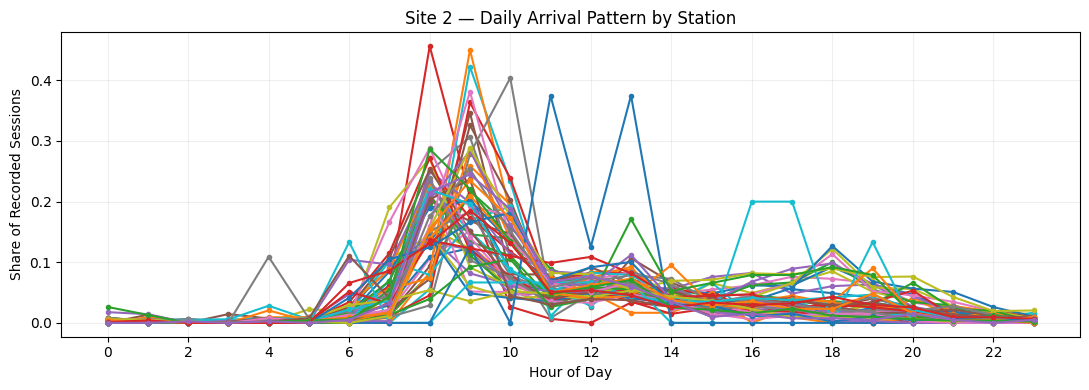

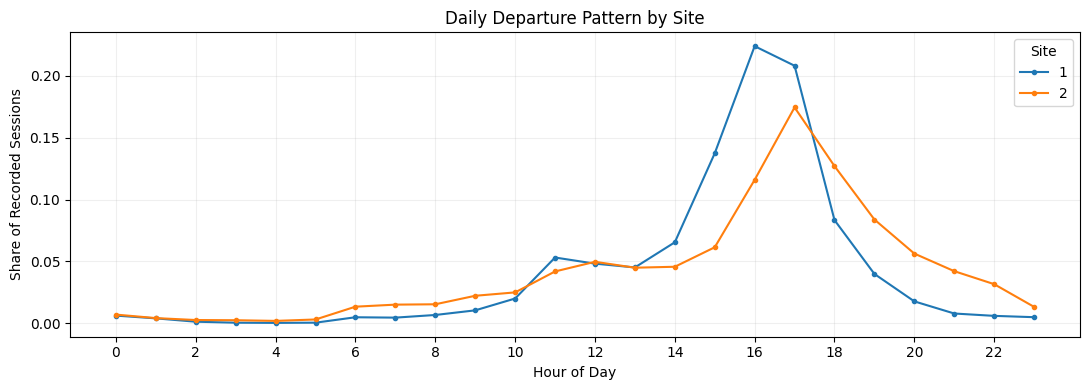

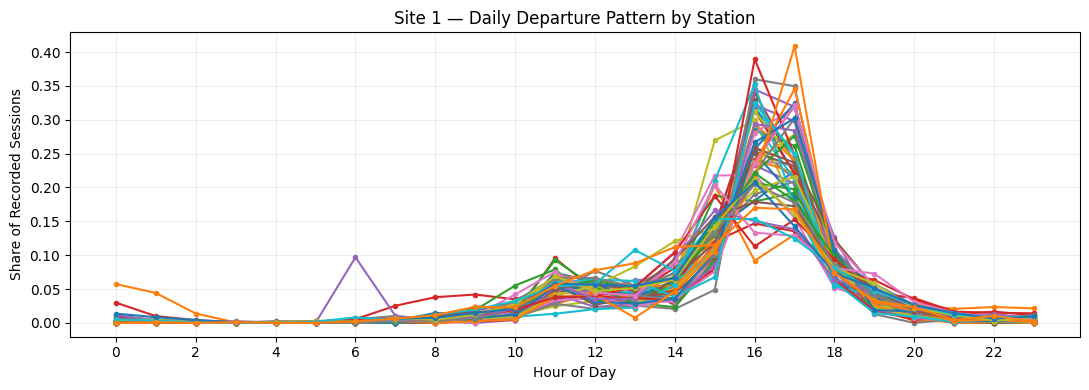

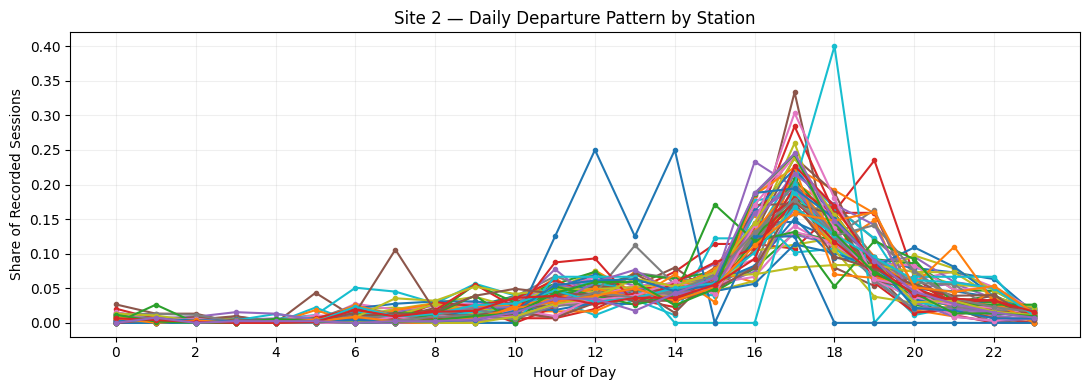

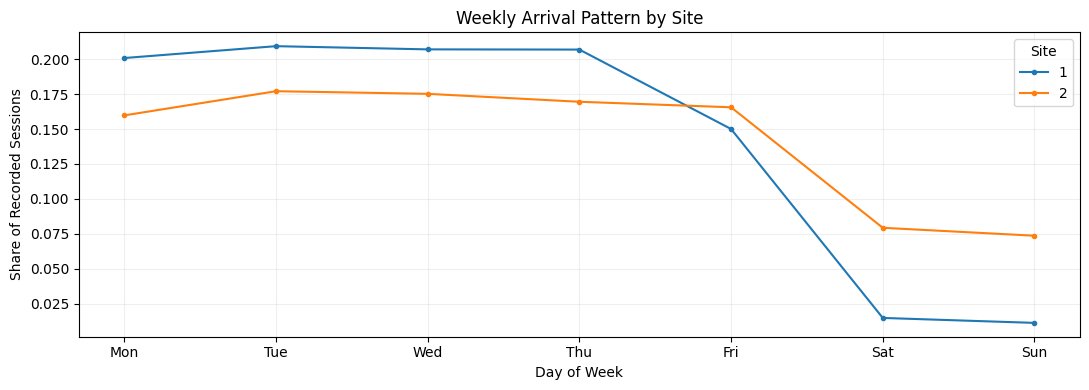

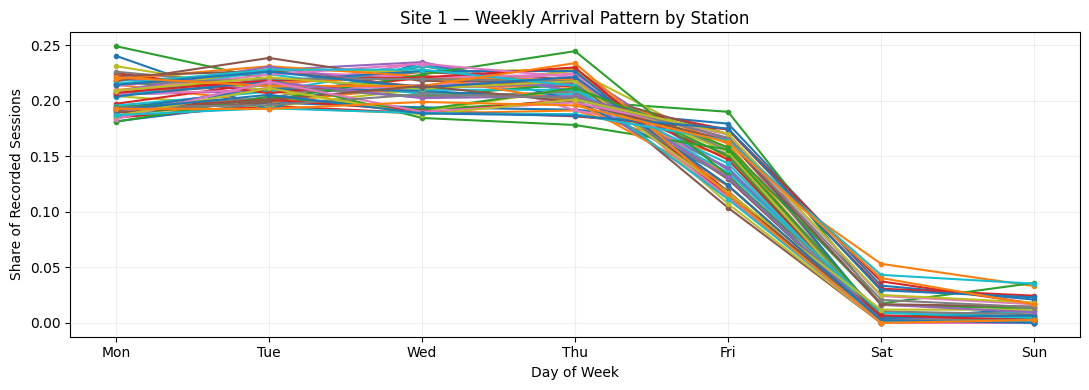

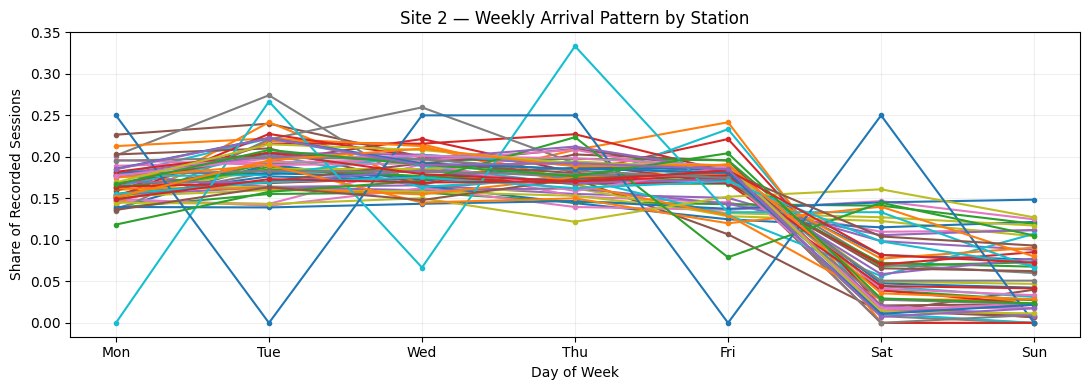

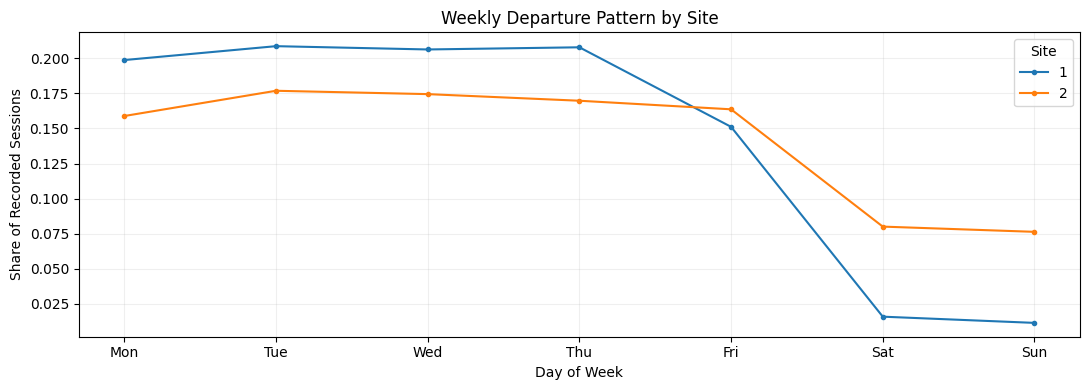

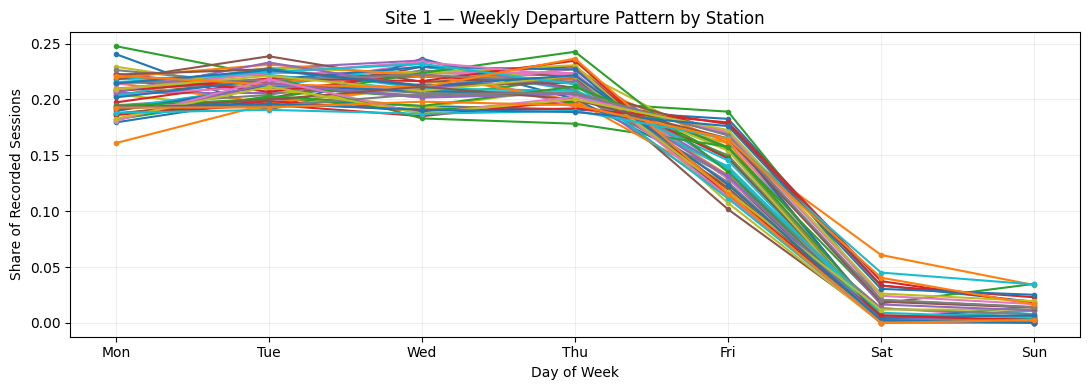

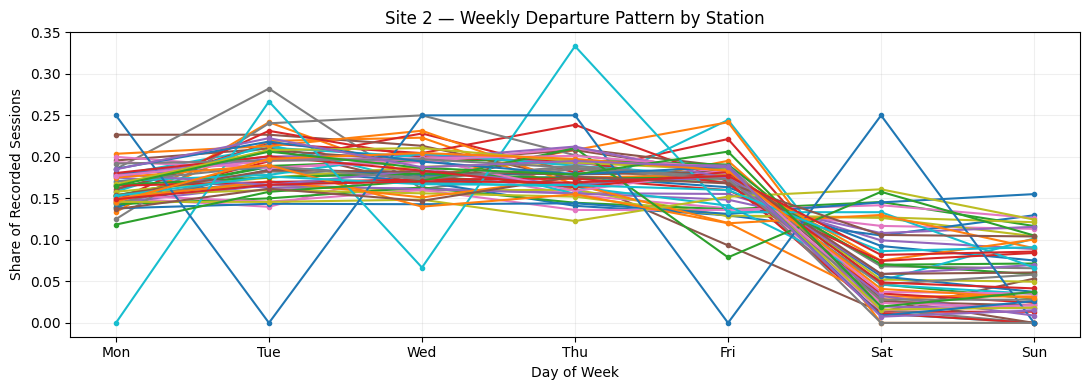

In [58]:
df = charging_sessions.copy()

# Local time
df["arrival_hour"] = df["connectionTime"].dt.hour
df["departure_hour"] = df["disconnectTime"].dt.hour
df["arrival_weekday"] = df["connectionTime"].dt.dayofweek
df["departure_weekday"] = df["disconnectTime"].dt.dayofweek

# Station labels include Site ID
df["site_station"] = (
    "Site " + df["siteID"].astype(str)
    + " / Station " + df["stationID"].astype(str)
)

def plot_time_pattern(data, time_col, group_col, title, weekly=False):

    index = range(7) if weekly else range(24)

    counts = (
        data.groupby([time_col, group_col])
        .size()
        .unstack(fill_value=0)
        .reindex(index, fill_value=0)
    )

    # Relative frequency within each Site / Station
    frequency = counts.div(
        counts.sum(axis=0).replace(0, float("nan")),
        axis=1
    )

    ax = frequency.plot(
        figsize=(11, 4),
        marker=".",
        linewidth=1.5
    )

    ax.set_title(title)
    ax.set_ylabel("Share of Recorded Sessions")
    ax.set_xlabel("Day of Week" if weekly else "Hour of Day")

    if weekly:
        ax.set_xticks(range(7))
        ax.set_xticklabels(
            ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
        )
    else:
        ax.set_xticks(range(0, 24, 2))

    ax.grid(alpha=0.2)
    if group_col == "siteID":
        ax.legend(title="Site", loc="upper right")
    else:
        ax.legend().remove()

    plt.tight_layout()
    plt.show()


features = [
    ("arrival_hour", "Daily Arrival Pattern", False),
    ("departure_hour", "Daily Departure Pattern", False),
    ("arrival_weekday", "Weekly Arrival Pattern", True),
    ("departure_weekday", "Weekly Departure Pattern", True)
]

for time_col, title, weekly in features:

    # 1. Compare sites
    plot_time_pattern(
        df, time_col, "siteID",
        f"{title} by Site", weekly
    )

    # 2. Compare stations within each site
    for site_id in sorted(df["siteID"].dropna().unique()):
        site_data = df[df["siteID"] == site_id]

        plot_time_pattern(
            site_data, time_col, "stationID",
            f"Site {site_id} — {title} by Station",
            weekly
        )

### Feature Engineering

| Dimension | Session Features | User Aggregation |
|---|---|---|
| Temporal Preference | Arrival hour, weekday | Circular mean, weekend share |
| Charging Demand | Energy delivered | Mean, SD |
| Parking Behavior | Connected duration | Mean, SD |
| Charging Behavior | Time until charging completed | Mean, SD |
| Flexibility Proxy | Post-charge idle duration, idle ratio | Mean, median |
| Regularity | Arrival time, inter-session gap | Circular dispersion, gap variability |
| Charging Frequency | Session date | Sessions per active week |


#

| Feature	| Clustering	| Adaptation |
|---|---|---|
| Arrival sin/cos	| ✓	| ✓ | 
| Weekend share	| ✓	| ✓ | 
| Mean energy	| ✓	| ✓ | 
| Mean connected hours	| ✓	| ✓ | 
| Mean charging hours	| optional	| ✓ | 
| Mean idle ratio	| opyional	| ✓ | 
| Charging frequency	| ✓	| ✓ | 
| Behavioral variability	| opyional	| ✓ | 

 **1. User Clustering — Between-user Heterogeneity**
Identify different types of EV charging behavior across users.

Data Structure:
- One row per user.
- Features include behavioral means, variability, frequency, and regularity.
- K-means / Gaussian Mixture Models (GMM) / HDBSCAN

**2. Behavioral Adaptation — Within-user Adaptation**
Analyze how individual users' charging behavior changes over time.

Data Structure:
- One row per user per month.
- Use consistent behavioral features across time periods.

Research Questions:
1. Does user charging behavior become more stable over time?
2. Do users change their preferred charging times?
3. Do users transition between different behavioral clusters?
4. How are behavioral changes associated with time, seasonality, or other observable factors?

In [2]:
# Feature Engineering
df = charging_sessions.loc[~charging_sessions["invalid_connection_time"]& charging_sessions["kWhDelivered"].gt(0)].copy()

# Session-level Features
# Temporal features
df["date"] = df["connectionTime"].dt.tz_localize(None)
df["month"] = df["date"].dt.to_period("M")
df["quarter"] = df["date"].dt.to_period("Q")
df["arrival_hour"] = df["date"].dt.hour + df["date"].dt.minute / 60
df["departure_hour"] = (df["disconnectTime"].dt.hour+ df["disconnectTime"].dt.minute / 60)
df["arrival_weekday"] = df["date"].dt.dayofweek
df["is_weekend"] = df["arrival_weekday"].ge(5).astype(int)
# Cyclical temporal features
df["arrival_sin"] = np.sin(2 * np.pi * df["arrival_hour"] / 24)
df["arrival_cos"] = np.cos(2 * np.pi * df["arrival_hour"] / 24)
df["month_sin"] = np.sin(2 * np.pi * df["date"].dt.month / 12)
df["month_cos"] = np.cos(2 * np.pi * df["date"].dt.month / 12)
# Duration features
df["connected_hours"] = df["connected_duration_hours"]
df["charging_hours"] = df["charging_duration_hours"]
df["idle_hours"] = (df["connected_hours"] - df["charging_hours"]).clip(lower=0)
df["idle_ratio"] = (df["idle_hours"] / df["connected_hours"].replace(0, np.nan))
# Energy features
df["energy_kWh"] = df["kWhDelivered"]
df["avg_power_kW"] = (df["energy_kWh"] / df["charging_hours"].replace(0, np.nan))
# Regularity fatures
df = df.sort_values(["siteID", "userID", "connectionTime"])
df["inter_session_days"] = (df.groupby(["siteID", "userID"])["connectionTime"].diff().dt.total_seconds() / 86400)

# User-level Features — Clustering
user_features = (
    df.dropna(subset=["userID"])
    .groupby(["siteID", "userID"])
    .agg(
        # Frequency
        session_count=("sessionID", "size"),
        # Temporal preference
        arrival_sin=("arrival_sin", "mean"),
        arrival_cos=("arrival_cos", "mean"),
        weekend_share=("is_weekend", "mean"),
        # Charging demand
        mean_energy_kWh=("energy_kWh", "mean"),
        sd_energy_kWh=("energy_kWh", "std"),
        # Parking behavior
        mean_connected_hours=("connected_hours", "mean"),
        sd_connected_hours=("connected_hours", "std"),
        # Charging behavior
        mean_charging_hours=("charging_hours", "mean"),
        sd_charging_hours=("charging_hours", "std"),
        # Flexibility proxy
        mean_idle_hours=("idle_hours", "mean"),
        median_idle_hours=("idle_hours", "median"),
        mean_idle_ratio=("idle_ratio", "mean"),
        # Regularity
        mean_inter_session_days=("inter_session_days", "mean"),
        sd_inter_session_days=("inter_session_days", "std"),
        # Observation period
        first_session=("date", "min"),
        last_session=("date", "max")
    )
    .reset_index()
)

# Frequency over observed time span
user_features["observation_months"] = ((user_features["last_session"] - user_features["first_session"]).dt.total_seconds() / (86400 * 30.4375))
user_features["sessions_per_month"] = (user_features["session_count"] / user_features["observation_months"].clip(lower=1))


# User-month Features — Behavioral Adaptation
user_month_features = (
    df.dropna(subset=["userID"])
    .groupby(["siteID", "userID", "month"])
    .agg(
        # Frequency
        session_count=("sessionID", "size"),

        # Temporal preference
        arrival_sin=("arrival_sin", "mean"),
        arrival_cos=("arrival_cos", "mean"),
        weekend_share=("is_weekend", "mean"),

        # Charging demand
        mean_energy_kWh=("energy_kWh", "mean"),
        sd_energy_kWh=("energy_kWh", "std"),

        # Parking behavior
        mean_connected_hours=("connected_hours", "mean"),
        sd_connected_hours=("connected_hours", "std"),

        # Charging behavior
        mean_charging_hours=("charging_hours", "mean"),
        sd_charging_hours=("charging_hours", "std"),

        # Flexibility proxy
        mean_idle_hours=("idle_hours", "mean"),
        median_idle_hours=("idle_hours", "median"),
        mean_idle_ratio=("idle_ratio", "mean"),

        # Regularity
        mean_inter_session_days=("inter_session_days", "mean"),
        sd_inter_session_days=("inter_session_days", "std")
    )
    .reset_index()
)

user_month_features["sessions_per_month"] = (user_month_features["session_count"])

NameError: name 'np' is not defined